In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [19]:
df = pd.read_csv("StudentPerformanceFactors.csv")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [20]:
# Check Dataset Information

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape:
(6607, 20)

Column Names:
Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities

In [21]:
#Check Missing Values

print(df.isnull().sum())

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


In [22]:
#Create the Target Variable

# Find the median exam score
median_score = df["Exam_Score"].median()

print("Median Exam Score:", median_score)

# Create Pass_Fail column
df["Pass_Fail"] = (df["Exam_Score"] >= median_score).astype(int)

# Check number of students in each class
print("\nPass/Fail Distribution:")
print(df["Pass_Fail"].value_counts())

Median Exam Score: 67.0

Pass/Fail Distribution:
Pass_Fail
1    3725
0    2882
Name: count, dtype: int64


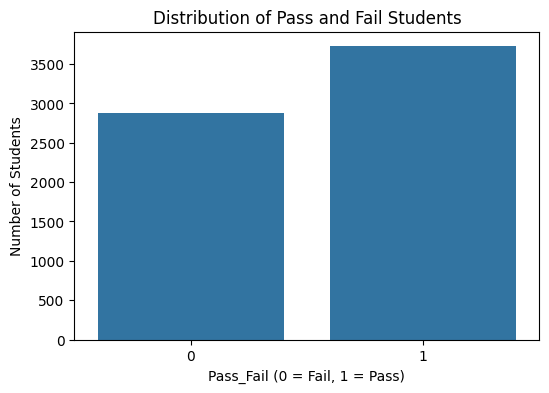

In [23]:
#Check Target Distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Pass_Fail")

plt.title("Distribution of Pass and Fail Students")
plt.xlabel("Pass_Fail (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")

plt.show()

In [24]:
#Select Features and Target

# Input features
X = df.drop(columns=["Exam_Score", "Pass_Fail"])

# Target variable
y = df["Pass_Fail"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Pass_Fail")

Features:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Target:
Pass_Fail


In [25]:
# Separate Numerical and Categorical Columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

Categorical Features:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [26]:
# Create the Preprocessing Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [27]:
# Split Training and Testing Data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (5285, 19)
Testing Data Shape: (1322, 19)


In [28]:
# Create the Logistic Regression Model

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [29]:
# Train the Model

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [30]:
# Make Predictions

y_pred = model.predict(X_test)

print("First 10 Predictions:")
print(y_pred[:10])

First 10 Predictions:
[1 0 1 1 1 0 1 0 0 1]


In [31]:
# Check Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 97.73 %


In [32]:
# Classification Report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.97      0.97       577
           1       0.98      0.98      0.98       745

    accuracy                           0.98      1322
   macro avg       0.98      0.98      0.98      1322
weighted avg       0.98      0.98      0.98      1322



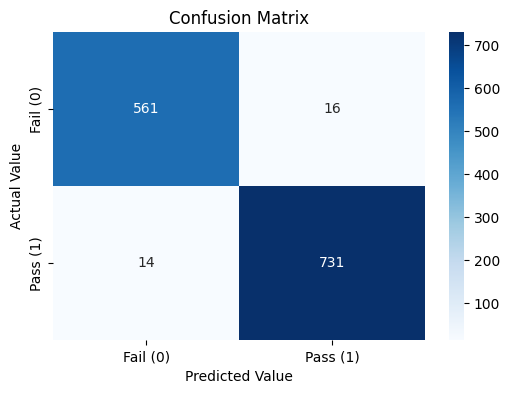

In [33]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail (0)", "Pass (1)"],
    yticklabels=["Fail (0)", "Pass (1)"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")

plt.show()

In [34]:
# Predict a New Student

new_student = pd.DataFrame({
    "Hours_Studied": [25],
    "Attendance": [90],
    "Parental_Involvement": ["High"],
    "Access_to_Resources": ["High"],
    "Extracurricular_Activities": ["Yes"],
    "Sleep_Hours": [7],
    "Previous_Scores": [80],
    "Motivation_Level": ["High"],
    "Internet_Access": ["Yes"],
    "Tutoring_Sessions": [3],
    "Family_Income": ["Medium"],
    "Teacher_Quality": ["High"],
    "School_Type": ["Private"],
    "Peer_Influence": ["Positive"],
    "Physical_Activity": [3],
    "Learning_Disabilities": ["No"],
    "Parental_Education_Level": ["College"],
    "Distance_from_Home": ["Near"],
    "Gender": ["Female"]
})

prediction = model.predict(new_student)[0]
probability = model.predict_proba(new_student)[0][1]

if prediction == 1:
    print("Prediction: PASS / HIGHER PERFORMANCE")
else:
    print("Prediction: FAIL / LOWER PERFORMANCE")

print("Probability of Pass:", round(probability * 100, 2), "%")

Prediction: PASS / HIGHER PERFORMANCE
Probability of Pass: 100.0 %
